# Praktikum Pertemuan 3 — Menyiapkan Data Proyek agar Layak dan Aman Dianalisis

**Mata Kuliah:** Exploratory Data Analysis (KMTI21133) — Pertemuan 3  
**Fase PjBL:** Perencanaan  
**Sub-CPMK3:** Mahasiswa mampu merumuskan pertanyaan analisis dari masalah nyata serta memperoleh data
sesuai lisensi sumbernya, serta mengidentifikasi dan menangani data pribadi yang terkandung di dalamnya (C4, A3).

**Cara kerja.** Sel bertanda `# TODO` Anda kerjakan sendiri; setiap TODO disertai *expected output* agar Anda bisa memeriksa jawaban sendiri. Sel Markdown bertanda **Jawaban Anda** diisi dengan tulisan, bukan kode.

**Bagian A–F** dikerjakan di kelas dengan dataset latihan. **Bagian G** dikerjakan bersama tim di luar kelas dengan dataset proyek Anda sendiri, dan hasilnya menjadi isi **M1 (bobot 5%)** yang dikumpulkan sesuai tenggat di LMS.

## Bagian 0 — Persiapan

Dataset latihan: **`saham-daily-2024.csv`** — 620 baris, 28 kolom.
Data pendaftaran dan hasil pelatihan UMKM binaan kampus.

> **Catatan penting:** seluruh isi dataset ini **sintetis** dan dibuat untuk latihan. Tidak ada orang nyata di dalamnya.
> Nomor NIK, nomor telepon, dan surel sengaja dibuat dengan pola yang tidak valid. Perlakukan tetap seolah-olah data nyata,
> karena itulah kebiasaan yang sedang kita latih.

---
## M1

Bagian ini adalah isi **M1**. Kerjakan bersama tim pada dataset proyek Anda sendiri.

### G1 — Pertanyaan analisis
Tulis **3–5 pertanyaan** yang lolos tiga uji. Untuk setiap pertanyaan, sebutkan kolom yang akan dipakai.

1. Pertanyaan Payung (Utama)

**Pertanyaan**: Bagaimana pergerakan tren likuiditas (volume dan frekuensi transaksi) di pasar saham sepanjang periode pengamatan di tahun 2024?

**Kolom yang dipakai**: Tanggal Perdagangan Terakhir, Volume, Frekuensi

2. Pertanyaan Turunan 1 (Analisis Volatilitas)

**Pertanyaan**: Sepuluh kode saham apa yang memiliki rata-rata selisih harga harian (volatilitas) tertinggi sepanjang tahun?

**Kolom yang dipakai**: Kode Saham, Tertinggi, Terendah (atau menggunakan kolom Selisih)

3. Pertanyaan Turunan 2 (Analisis Asing/Foreign)

**Pertanyaan**: Kode saham apa saja yang mencatatkan akumulasi volume beli asing (Foreign Buy) lebih besar daripada jual asing (Foreign Sell)?

**Kolom yang dipakai**: Kode Saham, Foreign Buy, Foreign Sell

4. Pertanyaan Turunan 3 (Analisis Nilai Transaksi)

**Pertanyaan**: Bagaimana sebaran nilai transaksi (Nilai) pada saham-saham yang ditutup menguat (harga Penutupan lebih besar dari harga Sebelumnya) dibandingkan saham yang melemah?

**Kolom yang dipakai**: Sebelumnya, Penutupan, Nilai

### G2 — Provenans data
Catat lima butir berikut di README repositori tim:

| Butir | Isi |
|---|---|
| Nama sumber | Dataset Ringkasan Perdagangan Harian Saham BEI 2024 (`saham-daily-2024.csv`) |
| Tautan atau nama instansi | Bursa Efek Indonesia (IDX) — https://www.idx.co.id |
| Tanggal pengambilan | 28 September 2026 |
| Lisensi atau nomor surat izin | Open Data / Publikasi Data Statistik Resmi BEI |
| Kalimat sitasi untuk laporan | Bursa Efek Indonesia. (2024). *Ringkasan Perdagangan Harian Saham Indonesia Tahun 2024*. Jakarta: PT Bursa Efek Indonesia. |

In [ ]:
# ==========================================
# 1. SETUP ENVIRONMENT & LOAD DATA
# ==========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Atur style plot
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# Memuat dataset (Pastikan file 'saham-daily-2024.csv' sudah diunggah ke Google Colab)
file_path = 'saham-daily-2024.csv'
df = pd.read_csv(file_path)

# Formatting tanggal
df['Tanggal'] = pd.to_datetime(df['Tanggal Perdagangan Terakhir'], format='%d %b %Y', errors='coerce')

print("✅ Data berhasil dimuat!")
print(f"Total baris data: {len(df):,}")
print(f"Rentang tanggal: {df['Tanggal'].min().strftime('%d %B %Y')} s.d. {df['Tanggal'].max().strftime('%d %B %Y')}")
display(df.head())

✅ Data berhasil dimuat!
Total baris data: 220,952
Rentang tanggal: 02 January 2024 s.d. 29 November 2024


,Unnamed: 0,No,Kode Saham,Nama Perusahaan,Remarks,Sebelumnya,Open Price,Tanggal Perdagangan Terakhir,First Trade,Tertinggi,Terendah,Penutupan,Selisih,Volume,Nilai,Frekuensi,Index Individual,Offer,Offer Volume,Bid,Bid Volume,Listed Shares,Tradeble Shares,Weight For Index,Foreign Sell,Foreign Buy,Non Regular Volume,Non Regular Value,Non Regular Frequency,Tanggal
0,0,1,AALI,Astra Agro Lestari Tbk.,--S-18AE106000D232------------,7000,0,29 Jan 2024,0,7050,6925,6975,-25,237600,1656220000,352,566.6,6975,29900,6950,44900,1924688333,1924688333,390711732,15100,35200,0,0,0,2024-01-29
1,1,2,ABBA,Mahaka Media Tbk.,--U-4100000000E614-E---------X,51,0,29 Jan 2024,0,53,50,51,0,27007600,1386034400,263,112.7,52,2519300,51,614800,3935892857,3935892857,1342139464,800,3030400,0,0,0,2024-01-29
2,2,3,ABDA,Asuransi Bina Dana Arta Tbk.,--U-4105000000G412-----------X,5500,0,29 Jan 2024,0,0,0,5500,0,0,0,0,1255.7,5500,5300,0,0,620806680,620806680,31474899,0,0,0,0,0,2024-01-29
3,3,4,ABMM,ABM Investama Tbk.,--S-1805000000A121------------,3410,0,29 Jan 2024,0,3430,3370,3380,-30,715300,2426665000,489,90.1,3390,7300,3380,10600,2753165000,2753165000,568803889,153900,39300,0,0,0,2024-01-29
4,4,5,ACES,Ace Hardware Indonesia Tbk.,--SO1S75MD0000E743------------,820,820,29 Jan 2024,820,835,815,835,15,44594700,36864395500,3135,1018.3,835,8148300,830,18600,17150000000,17150000000,6832560000,28298800,18010200,0,0,0,2024-01-29



--- RINGKASAN LIKUIDITAS BULANAN ---


,Tanggal_Str,Trading_Days,Avg_Daily_Volume,Avg_Daily_Frekuensi,Total_Nilai
0,2024-01,22,1.516611e+10,1.173094e+06,191642901895400
1,2024-02,18,1.577152e+10,1.231816e+06,170177897880600
2,2024-03,18,1.493645e+10,1.150229e+06,170426067525300
3,2024-04,16,1.362029e+10,1.118815e+06,184127900234000
4,2024-06,18,1.442919e+10,8.705525e+05,158383262814300
5,2024-07,23,1.448727e+10,9.999836e+05,190948001489100
6,2024-09,20,2.011236e+10,1.218519e+06,234256933825600
7,2024-11,20,2.022635e+10,1.208194e+06,207536780394100


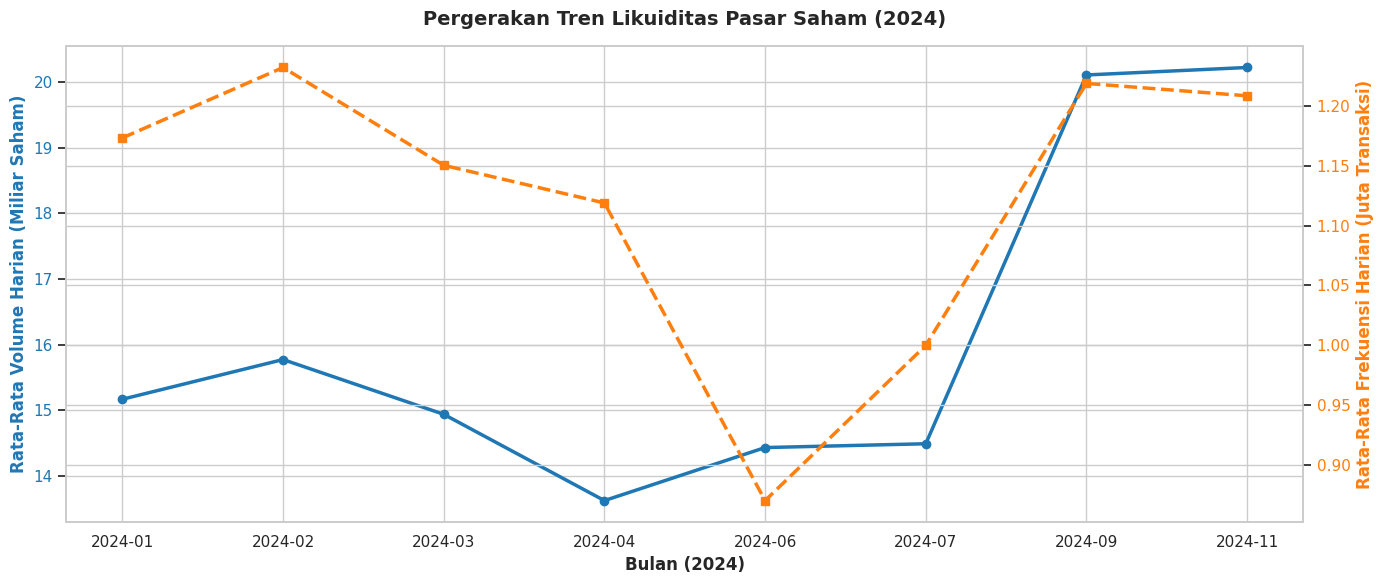

In [ ]:
# ==========================================
# 2. PERTANYAAN UTAMA: TREN LIKUIDITAS
# ==========================================
# Agregasi bulanan
df_monthly = df.groupby(df['Tanggal'].dt.to_period('M')).agg(
    Trading_Days=('Tanggal', 'nunique'),
    Total_Volume=('Volume', 'sum'),
    Total_Frekuensi=('Frekuensi', 'sum'),
    Total_Nilai=('Nilai', 'sum')
).reset_index()

df_monthly['Avg_Daily_Volume'] = df_monthly['Total_Volume'] / df_monthly['Trading_Days']
df_monthly['Avg_Daily_Frekuensi'] = df_monthly['Total_Frekuensi'] / df_monthly['Trading_Days']
df_monthly['Tanggal_Str'] = df_monthly['Tanggal'].astype(str)

print("\n--- RINGKASAN LIKUIDITAS BULANAN ---")
display(df_monthly[['Tanggal_Str', 'Trading_Days', 'Avg_Daily_Volume', 'Avg_Daily_Frekuensi', 'Total_Nilai']])

# Plot Tren Likuiditas
fig, ax1 = plt.subplots(figsize=(14, 6))

color = 'tab:blue'
ax1.set_xlabel('Bulan (2024)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Rata-Rata Volume Harian (Miliar Saham)', color=color, fontsize=12, fontweight='bold')
line1 = ax1.plot(df_monthly['Tanggal_Str'], df_monthly['Avg_Daily_Volume'] / 1e9, color=color, marker='o', linewidth=2.5, label='Volume Harian')
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Rata-Rata Frekuensi Harian (Juta Transaksi)', color=color, fontsize=12, fontweight='bold')
line2 = ax2.plot(df_monthly['Tanggal_Str'], df_monthly['Avg_Daily_Frekuensi'] / 1e6, color=color, marker='s', linewidth=2.5, linestyle='--', label='Frekuensi Harian')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Pergerakan Tren Likuiditas Pasar Saham (2024)', fontsize=14, fontweight='bold', pad=15)
fig.tight_layout()
plt.show()


--- TOP 10 SAHAM PALING VOLATIL ---


,Kode Saham,Nama Perusahaan,Rata_Rentang_Harian,Rata_Abs_Selisih
275,DSSA,Dian Swastatika Sentosa Tbk,3302.004219,2387.130802
728,PTRO,Petrosea Tbk.,645.590717,335.337553
248,DCII,DCI Indonesia Tbk.,611.603376,502.953586
0,AADI,Adaro Andalan Indonesia Tbk.,539.062500,523.437500
590,MLPT,Multipolar Technology Tbk.,514.367089,320.337553
915,UNTR,United Tractors Tbk.,510.443038,302.320675
243,DAAZ,Daaz Bara Lestari Tbk.,478.484848,332.121212
887,TPIA,Chandra Asri Petrochemical Tbk.,477.600000,257.600000
443,ITMG,Indo Tambangraya Megah Tbk.,455.063291,272.784810
241,CUAN,Petrindo Jaya Kreasi Tbk.,450.886076,262.320675


/tmp/ipykernel_1752/2340222935.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top10_volatilitas, x='Rata_Rentang_Harian', y='Kode Saham', palette='Reds_r')


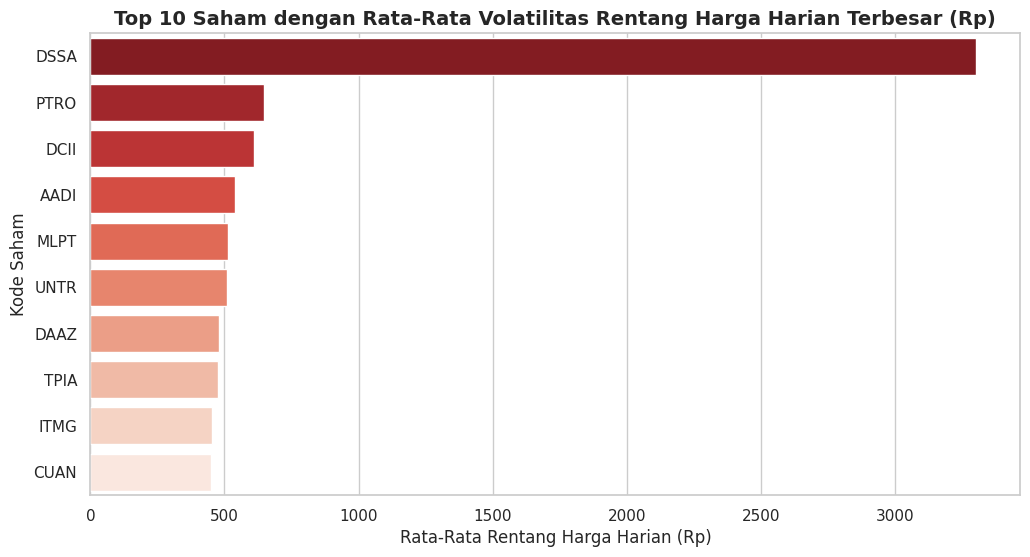

In [ ]:
# ==========================================
# 3. TURUNAN 1: VOLATILITAS HARGA HARIAN
# ==========================================
# Menghitung Rentang Harian (Tertinggi - Terendah) dan Absolut Perubahan (|Selisih|)
df['Daily_Range'] = df['Tertinggi'] - df['Terendah']
df['Abs_Selisih'] = df['Selisih'].abs()

# Top 10 Volatilitas
top10_volatilitas = df.groupby(['Kode Saham', 'Nama Perusahaan']).agg(
    Rata_Rentang_Harian=('Daily_Range', 'mean'),
    Rata_Abs_Selisih=('Abs_Selisih', 'mean')
).reset_index().sort_values(by='Rata_Rentang_Harian', ascending=False).head(10)

print("\n--- TOP 10 SAHAM PALING VOLATIL ---")
display(top10_volatilitas)

# Plot Top 10 Volatilitas
plt.figure(figsize=(12, 6))
sns.barplot(data=top10_volatilitas, x='Rata_Rentang_Harian', y='Kode Saham', palette='Reds_r')
plt.title('Top 10 Saham dengan Rata-Rata Volatilitas Rentang Harga Harian Terbesar (Rp)', fontsize=14, fontweight='bold')
plt.xlabel('Rata-Rata Rentang Harga Harian (Rp)', fontsize=12)
plt.ylabel('Kode Saham', fontsize=12)
plt.show()


--- TOP 10 AKUMULASI BELI ASING (NET FOREIGN BUY) ---


,Kode Saham,Nama Perusahaan,Total_Foreign_Buy,Total_Foreign_Sell,Net_Foreign_Buy
132,BIPI,Astrindo Nusantara Infrastruktur Tbk.,16063888900,5472770500,10591118400
187,BULL,Buana Lintas Lautan Tbk.,10573577600,3159244600,7414333000
651,OASA,Maharaksa Biru Energi Tbk.,6956371600,1137084500,5819287100
305,EURO,Estee Gold Feet Tbk.,2824379500,418493100,2405886400
442,ITMA,Sumber Energi Andalan Tbk.,1999413800,297043200,1702370600
477,KIJA,Kawasan Industri Jababeka Tbk.,3642694200,2549287800,1093406400
498,KPIG,MNC Land Tbk.,6212109800,5418297100,793812700
123,BFIN,BFI Finance Indonesia Tbk.,1599580100,853208800,746371300
886,TPIA,Chandra Asri Pacific Tbk.,2669225700,1937362000,731863700
678,PGAS,Perusahaan Gas Negara Tbk.,4083042800,3360133100,722909700


/tmp/ipykernel_1752/586925082.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top10_net_foreign, x=top10_net_foreign['Net_Foreign_Buy'] / 1e9, y='Kode Saham', palette='Greens_r')


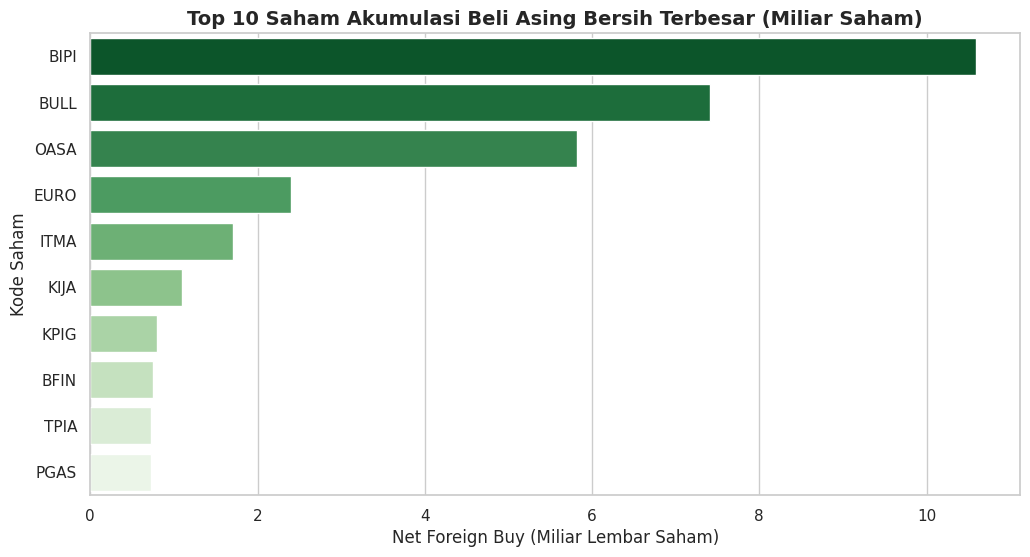

In [ ]:
# ==========================================
# 4. TURUNAN 2: AKUMULASI TRANSAKSI ASING
# ==========================================
df_foreign = df.groupby(['Kode Saham', 'Nama Perusahaan']).agg(
    Total_Foreign_Buy=('Foreign Buy', 'sum'),
    Total_Foreign_Sell=('Foreign Sell', 'sum')
).reset_index()

df_foreign['Net_Foreign_Buy'] = df_foreign['Total_Foreign_Buy'] - df_foreign['Total_Foreign_Sell']
top10_net_foreign = df_foreign.sort_values(by='Net_Foreign_Buy', ascending=False).head(10)

print("\n--- TOP 10 AKUMULASI BELI ASING (NET FOREIGN BUY) ---")
display(top10_net_foreign)

# Plot Net Foreign Buy
plt.figure(figsize=(12, 6))
sns.barplot(data=top10_net_foreign, x=top10_net_foreign['Net_Foreign_Buy'] / 1e9, y='Kode Saham', palette='Greens_r')
plt.title('Top 10 Saham Akumulasi Beli Asing Bersih Terbesar (Miliar Saham)', fontsize=14, fontweight='bold')
plt.xlabel('Net Foreign Buy (Miliar Lembar Saham)', fontsize=12)
plt.ylabel('Kode Saham', fontsize=12)
plt.show()


--- SEBARAN NILAI TRANSAKSI BERDASARKAN STATUS PERGERAKAN HARGA ---


,Status,Jumlah_Kejadian,Total_Nilai_Triliun,Rata2_Nilai_Miliar,Median_Nilai_Juta
0,Melemah (Losers),74988,1038.882080,13.853978,249.33115
1,Menguat (Gainers),64630,1118.234608,17.302098,356.75940
2,Stagnan (Unchanged),81334,193.629834,2.380675,4.89210


/tmp/ipykernel_1752/2434575114.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[0], data=summary_status, x='Status', y='Total_Nilai_Triliun', palette='Set2')
/tmp/ipykernel_1752/2434575114.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[1], data=summary_status, x='Status', y='Rata2_Nilai_Miliar', palette='Set2')


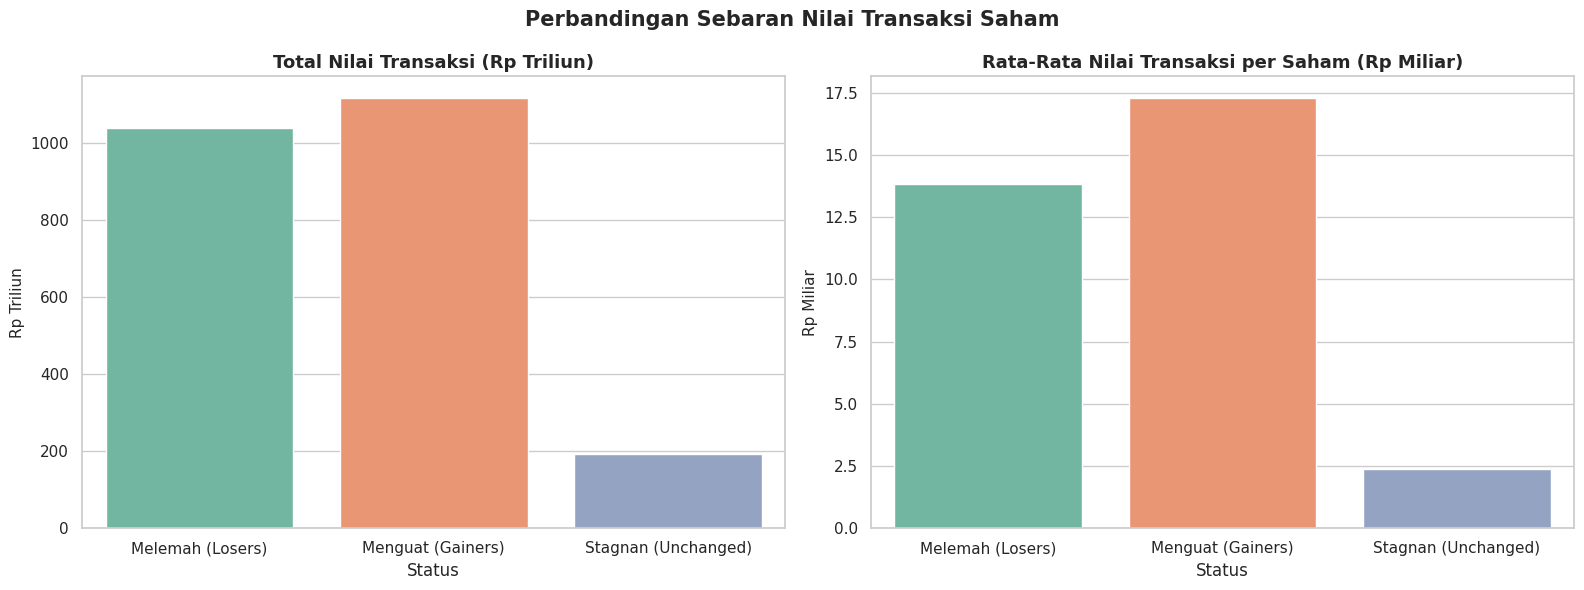

In [ ]:
# ==========================================
# 5. TURUNAN 3: SEBARAN NILAI TRANSAKSI
# ==========================================
def kategorikan_status(row):
    if row['Penutupan'] > row['Sebelumnya']:
        return 'Menguat (Gainers)'
    elif row['Penutupan'] < row['Sebelumnya']:
        return 'Melemah (Losers)'
    else:
        return 'Stagnan (Unchanged)'

df['Status'] = df.apply(kategorikan_status, axis=1)

summary_status = df.groupby('Status').agg(
    Jumlah_Kejadian=('Nilai', 'count'),
    Total_Nilai_Triliun=('Nilai', lambda x: x.sum() / 1e12),
    Rata2_Nilai_Miliar=('Nilai', lambda x: x.mean() / 1e9),
    Median_Nilai_Juta=('Nilai', lambda x: x.median() / 1e6)
).reset_index()

print("\n--- SEBARAN NILAI TRANSAKSI BERDASARKAN STATUS PERGERAKAN HARGA ---")
display(summary_status)

# Plot Sebaran Nilai Transaksi
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Total Nilai Transaksi
sns.barplot(ax=axes[0], data=summary_status, x='Status', y='Total_Nilai_Triliun', palette='Set2')
axes[0].set_title('Total Nilai Transaksi (Rp Triliun)', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Rp Triliun', fontsize=11)

# Subplot 2: Rata-rata Nilai Transaksi per Saham
sns.barplot(ax=axes[1], data=summary_status, x='Status', y='Rata2_Nilai_Miliar', palette='Set2')
axes[1].set_title('Rata-Rata Nilai Transaksi per Saham (Rp Miliar)', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Rp Miliar', fontsize=11)

plt.suptitle('Perbandingan Sebaran Nilai Transaksi Saham', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()